### Top Rows

In [396]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display, HTML

def display_scroll(df, height="400px"):
    display(HTML(f"""
    <div style="max-height:{height}; overflow:auto; border:1px solid #ccc; padding:5px;">
        {df.to_html()}
    </div>
    """))
    
file_path = "results-filtered.xlsx"

df = pd.read_excel(file_path, sheet_name="kPEX")
versions="v0 v1 v2 v3 v4".split()

# df = pd.read_excel(file_path, sheet_name="UMKP+AltRB")
# versions="v0 v1 v2 v3".split()

branchings="S R P".split()

for v in versions: 
    df[f"{v}-prep"] = (df[f"{v}-S-bnb"] == "prep")
    cols = [f"{v}-{b}-ctcp" for b in branchings]
    df[f"{v}-ctcp"] = (
        df[cols]
        .apply(pd.to_numeric, errors="coerce")  # non-numeric → NaN
        .mean(axis=1)                           # skips NaN automatically
    )
    cols = [f"{v}-{b}-heur" for b in branchings]
    df[f"{v}-heur"] = (
        df[cols]
        .apply(pd.to_numeric, errors="coerce")  # non-numeric → NaN
        .mean(axis=1)                           # skips NaN automatically
    )    

    
def clean_dataframe(df):
    df = df.dropna(axis=1, how="all")
    df = df.copy()

    def convert_col(col):
        # replace exact matches first
        col = col.replace({"x": 1800, "prep": 0})
        
        # try numeric conversion WITHOUT destroying original values
        numeric = pd.to_numeric(col, errors="coerce")
        
        # keep original where conversion failed
        return numeric.where(~numeric.isna(), col)

    return df.apply(convert_col)

df = clean_dataframe(df)

for v in versions: 
    df[f"{v}-init"] = df[f"{v}-heur"]+df[f"{v}-ctcp"]
    df[f"{v}-prep"] = df[f"{v}-prep"].replace(False, "")
    
df.head()
pd.set_option('display.float_format', '{:.1f}'.format)
pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', None)

/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/2379099581.py:45: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  col = col.replace({"x": 1800, "prep": 0})
/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/2379099581.py:45: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  col = col.replace({"x": 1800, "prep": 0})
/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/2379099581.py:45: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To reta

In [386]:
# for v in versions: 
cols = [f"v0-{b}-mkp" for b in "S R P".split() ]
cols = [f"v{i}-{b}-mkp" for i in [0, 1] for b in "S".split() ]

mask = df[cols].apply(lambda row: row[row != 1800].nunique() > 1, axis=1)
display_scroll(df.loc[mask, cols+["dataset", "k", "v0-S-total", "v1-S-total"]])
filtered_df = df[mask]

filtered_df[["dataset", "k"]].to_excel("filtered_rows.xlsx", index=False)
mask.sum()

,v0-S-mkp,v1-S-mkp,dataset,k,v0-S-total,v1-S-total


np.int64(0)

### Varying Ratio Threshold


=== Threshold 1.2 Analysis ===
v0-S-total wins: 1407
v4-S-total wins: 61

--- Weaker side: v4-S-total ---


,dataset,k,v0-S-total,v4-S-total,speedup,v0-ctcp,v4-ctcp,v0-heur,v4-heur,v0-init,v4-init,v0-prep,v4-prep,v0-S-total,v4-S-total,v0-R-total,v4-R-total,v0-P-total,v4-P-total
3169,soc-bitcoin,2,1625.3,941.3,1.73x,1.8,2.8,0.2,0.2,1.9,3.0,,,1625.3,941.3,270.2,109.2,4.5,5.4
1452,G6,9,489.7,403.8,1.21x,0.0,0.0,0.0,0.0,0.0,0.0,,,489.7,403.8,1219.1,1027.8,598.2,517.2
4172,web-wikipedia_link_en13-a...,4,414.0,298.1,1.39x,306.3,299.6,111.2,1.6,417.5,301.2,True,True,414.0,298.1,420.5,291.8,418.2,313.6
4217,wikipedia-link-en13,4,606.5,292.0,2.08x,365.1,341.9,116.4,1.7,481.5,343.6,True,True,606.5,292.0,427.7,337.9,410.3,401.1
12,162bit,7,342.9,282.9,1.21x,0.0,0.0,1.9,2.0,1.9,2.0,,,342.9,282.9,1800.0,1800.0,1800.0,1800.0
4171,web-wikipedia_link_en13-a...,3,317.0,244.6,1.30x,255.6,255.1,59.2,1.1,314.8,256.2,True,True,317.0,244.6,314.1,246.2,313.3,277.7
4277,wikipedia_link_sr,3,295.2,59.6,4.96x,43.8,38.0,246.0,15.4,289.9,53.4,,,295.2,59.6,298.0,65.0,290.8,61.8
4286,wikipedia_link_sr,20,246.1,51.0,4.83x,44.2,40.9,202.5,10.1,246.7,51.0,True,True,246.1,51.0,246.7,51.6,247.2,50.3
4279,wikipedia_link_sr,5,240.6,49.7,4.84x,43.8,38.9,196.4,8.8,240.2,47.7,True,True,240.6,49.7,240.2,49.7,239.8,43.6
4278,wikipedia_link_sr,4,245.7,49.1,5.00x,43.6,37.7,199.5,9.9,243.0,47.6,True,True,245.7,49.1,241.6,49.4,241.7,44.3



--- Stronger side: v0-S-total ---


,dataset,k,v0-S-total,v4-S-total,speedup,v0-ctcp,v4-ctcp,v0-heur,v4-heur,v0-init,v4-init,v0-prep,v4-prep,v0-S-total,v4-S-total,v0-R-total,v4-R-total,v0-P-total,v4-P-total
886,degme,6,497.9,659.7,1.33x,0.1,0.1,0.0,0.1,0.1,0.2,,,497.9,659.7,498.4,796.3,498.5,580.6
887,degme,7,493.0,721.7,1.46x,0.1,0.1,0.0,0.1,0.1,0.2,,,493.0,721.7,494.9,746.5,497.2,607.6
888,degme,8,473.2,582.2,1.23x,0.1,0.1,0.0,0.1,0.1,0.2,,,473.2,582.2,469.8,599.7,470.1,540.4
889,degme,9,458.6,551.8,1.20x,0.1,0.1,0.0,0.0,0.1,0.2,,,458.6,551.8,454.8,635.9,453.8,557.8
890,degme,10,426.5,601.7,1.41x,0.1,0.1,0.0,0.0,0.1,0.2,,,426.5,601.7,423.4,683.2,428.1,493.1
4215,wikipedia-link-en13,2,267.1,334.8,1.25x,244.2,283.8,22.8,1.0,267.1,284.8,True,True,267.1,334.8,262.7,249.3,271.4,270.3
1963,livejournal-groupmembersh...,8,197.9,241.1,1.22x,94.4,121.6,36.8,47.3,131.2,168.9,,,197.9,241.1,204.0,252.8,199.6,215.0
1210,ESOC,8,185.5,238.0,1.28x,0.1,0.2,112.7,157.1,112.9,157.2,,,185.5,238.0,194.1,243.5,186.2,282.7
3974,TSOPF_FS_b39_c30,9,184.4,227.3,1.23x,0.1,0.2,93.4,104.1,93.5,104.3,,,184.4,227.3,184.1,206.7,185.4,224.4
1219,EternityII_E,6,137.0,165.4,1.21x,0.0,0.0,0.0,0.0,0.0,0.1,,,137.0,165.4,154.2,184.6,338.6,342.9


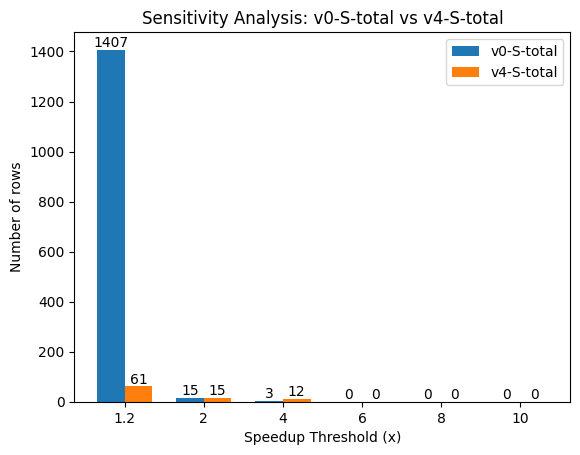

In [397]:
# =========================
# CONFIG
# =========================

col_a = "v0-S-total"
col_b = "v4-S-total"
va = col_a.split("-")[0]
vb = col_b.split("-")[0]
thresholds = [1.2, 2, 4, 6, 8, 10]
min_time_threshold = 1.0

# =========================
# Handle zeros
# =========================
df = df.replace(0, 0.01)

# =========================
# Filter
# =========================
df_filtered = df[
    (df[col_a] >= min_time_threshold) | (df[col_b] >= min_time_threshold)
].copy()

# =========================
# Compute speedups
# =========================
df_filtered["speedup_a"] = df_filtered[col_b] / df_filtered[col_a]
df_filtered["speedup_b"] = df_filtered[col_a] / df_filtered[col_b]

# =========================
# Threshold = 2 analysis
# =========================
threshold_check = thresholds[0]

a_wins = df_filtered[df_filtered["speedup_a"] >= threshold_check].copy()
b_wins = df_filtered[df_filtered["speedup_b"] >= threshold_check].copy()

# =========================
# Determine weaker & stronger
# =========================
if len(a_wins) < len(b_wins):
    weaker = "A"
    stronger = "B"
elif len(b_wins) < len(a_wins):
    weaker = "B"
    stronger = "A"
else:
    weaker = "Tie"
    stronger = "Tie"


# =========================
# Formatting function (SIDE-AWARE)
# =========================
max_len = 25

def format_df(df_in, side):
    if side == "A":
        speedup_series = df_in["speedup_a"].map(lambda x: f"{x:.2f}x")
        speedup_name = f"{col_b}/{col_a}"
    else:
        speedup_series = df_in["speedup_b"].map(lambda x: f"{x:.2f}x")
        speedup_name = f"{col_a}/{col_b}"

    return df_in.assign(
        dataset=df_in["dataset"].apply(
            lambda x: (str(x)[:max_len] + "...") if len(str(x)) > max_len else str(x)
        ),
        speedup=speedup_series
    )[[
        "dataset", "k",
        col_a, col_b,
        "speedup",
        f"{va}-ctcp", f"{vb}-ctcp",
        f"{va}-heur", f"{vb}-heur",
        f"{va}-init", f"{vb}-init",
        f"{va}-prep", f"{vb}-prep",
        f"{va}-S-total", f"{vb}-S-total",
        f"{va}-R-total", f"{vb}-R-total",
        f"{va}-P-total", f"{vb}-P-total"
    ]]
    # .rename(columns={"speedup": f"speedup ({speedup_name})"})

# =========================
# Print summary
# =========================
print(f"\n=== Threshold {threshold_check} Analysis ===")
print(f"{col_a} wins: {len(a_wins)}")
print(f"{col_b} wins: {len(b_wins)}")

# =========================
# Display results
# =========================
if weaker == "Tie":
    print("Both sides have equal wins.")

    print("\n--- Side A (>= threshold) ---")
    display_scroll(
        format_df(a_wins.sort_values(by=f"{col_a}", ascending=False), "A")
        # format_df(a_wins.sort_values(by="{speedup_a}", ascending=False), "A")
    )

    print("\n--- Side B (>= threshold) ---")
    display_scroll(
        format_df(b_wins.sort_values(by=f"{col_b}", ascending=False), "B")
        # format_df(a_wins.sort_values(by="{speedup_b}", ascending=False), "A")
    )

else:
    if weaker == "A":
        weaker_df = a_wins.sort_values(by=f"{col_a}", ascending=False)
        stronger_df = b_wins.sort_values(by=f"{col_b}", ascending=False)
        # weaker_df = a_wins.sort_values(by="speedup_a", ascending=False)
        # stronger_df = b_wins.sort_values(by="speedup_b", ascending=False)
        weaker_name, stronger_name = col_a, col_b

        print(f"\n--- Weaker side: {weaker_name} ---")
        display_scroll(format_df(weaker_df, "A"))

        print(f"\n--- Stronger side: {stronger_name} ---")
        display_scroll(format_df(stronger_df, "B"))

    else:
        weaker_df = b_wins.sort_values(by=f"{col_b}", ascending=False)
        stronger_df = a_wins.sort_values(by=f"{col_a}", ascending=False)
        # weaker_df = b_wins.sort_values(by="speedup_b", ascending=False)
        # stronger_df = a_wins.sort_values(by="speedup_a", ascending=False)
        weaker_name, stronger_name = col_b, col_a

        print(f"\n--- Weaker side: {weaker_name} ---")
        display_scroll(format_df(weaker_df, "B"))

        print(f"\n--- Stronger side: {stronger_name} ---")
        display_scroll(format_df(stronger_df, "A"))

# =========================
# Sensitivity analysis
# =========================
a_counts = []
b_counts = []

for t in thresholds:
    a_counts.append((df_filtered["speedup_a"] >= t).sum())
    b_counts.append((df_filtered["speedup_b"] >= t).sum())

# =========================
# Plot
# =========================
x = range(len(thresholds))
width = 0.35

plt.figure()

bars_a = plt.bar([i - width/2 for i in x], a_counts, width, label=col_a)
bars_b = plt.bar([i + width/2 for i in x], b_counts, width, label=col_b)

def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height,
            f"{int(height)}",
            ha='center',
            va='bottom'
        )

add_labels(bars_a)
add_labels(bars_b)

plt.xticks(x, thresholds)
plt.xlabel("Speedup Threshold (x)")
plt.ylabel("Number of rows")
plt.title(f"Sensitivity Analysis: {col_a} vs {col_b}")

plt.legend()
plt.show()